### **Naive Bayes End-to-End ML Pipeline — Group Lab (3 Members)**

**Goal:** As a group of **3**, build a complete pipeline that predicts Titanic passenger survival with **Naive Bayes** — from raw data all the way to a final, evaluated model. The lab is split into **3 parts**, one per group member, but **everyone should read and understand every part** — you'll need each other's outputs to finish the pipeline.

**Dataset:** We'll use `seaborn`'s **built-in** Titanic dataset — no download or upload needed:
```python
titanic = sns.load_dataset('titanic')
```
(If your instructor asks you to use a different/self-generated dataset instead, the same structure below still applies — just swap the loading step.)

**How the 3 parts connect (the pipeline, in order):**

| Part | Member | Focus | Concepts Covered |
|---|---|---|---|
| **1** | **A** | Explore the raw data | EDA, Data Visualization, Bayes' Theorem (by hand) |
| **2** | **B** | Clean & transform the data | Missing Values, Binning, Binarization, Ordinal/One-Hot/Label Encoding, Column Transformer, Function/Power Transformer, Standardization & Normalization |
| **3** | **C** | Build & evaluate the model | Naive Bayes (from scratch + `sklearn`), Cross-Validation, Evaluation Metrics |

**Rule:** Member B's final output (`X_train_final`, `X_test_final`, `y_train`, `y_test`) is exactly what Member C needs as input. Member A's Section 1.7 (Bayes' Theorem by hand) is the conceptual foundation Member C will re-use in Section 3.1. **Talk to each other before starting your part.**

Cells marked `# TODO` are where you write your own code. Everything else (imports, structure, explanations) is provided to keep the group in sync.

#### **0. Shared Setup (Everyone Runs This First)**

Run this section before splitting into your parts — it loads the libraries and the dataset every part depends on.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

%matplotlib inline
sns.set(style='whitegrid')


In [2]:
# Built-in dataset - no download required
titanic = sns.load_dataset('titanic')
titanic.head()


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


**A quick look at what we're working with:** each row is one passenger. Key columns: `survived` (target, 0/1), `pclass`, `sex`, `age`, `sibsp`, `parch`, `fare`, `embarked`, `who`, `alive` (text version of `survived`), `deck` (mostly missing).

#### **Part 1 (Member A): Exploratory Data Analysis & Bayes' Theorem Foundations**

**Your job:** understand the raw data before anyone touches it — its shape, quality issues, and the patterns that make Naive Bayes a sensible model choice here.

**1.1 Dataset Structure**

Check the shape, column data types, and general info of `titanic`.

In [3]:
print('Shape:',titanic.shape)
titanic.info()


Shape: (891, 15)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


**1.2 Statistical Summary**

`.describe()` gives count/mean/std/min/max/quartiles for numeric columns — a first look at scale and possible skew (e.g., compare `fare`'s mean vs its median/50%).

In [4]:
display(titanic.describe(include='all'))


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
count,891.000000,891.000000,891,714.000000,891.000000,891.000000,891.000000,889,891,891,891,203,889,891,891
unique,NaN,NaN,2,NaN,NaN,NaN,NaN,3,3,3,2,7,3,2,2
top,NaN,NaN,male,NaN,NaN,NaN,NaN,S,Third,man,True,C,Southampton,no,True
freq,NaN,NaN,577,NaN,NaN,NaN,NaN,644,491,537,537,59,644,549,537
mean,0.383838,2.308642,NaN,29.699118,0.523008,0.381594,32.204208,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,0.486592,0.836071,NaN,14.526497,1.102743,0.806057,49.693429,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,0.000000,1.000000,NaN,0.420000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,0.000000,2.000000,NaN,20.125000,0.000000,0.000000,7.910400,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,0.000000,3.000000,NaN,28.000000,0.000000,0.000000,14.454200,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,1.000000,3.000000,NaN,38.000000,1.000000,0.000000,31.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**1.3 Missing Value Analysis**

Which columns have missing data, and how much? This will guide Member B's cleaning strategy in Part 2.

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64
Missing %:
 survived        0.00
pclass          0.00
sex             0.00
age            19.87
sibsp           0.00
parch           0.00
fare            0.00
embarked        0.22
class           0.00
who             0.00
adult_male      0.00
deck           77.22
embark_town     0.22
alive           0.00
alone           0.00
dtype: float64


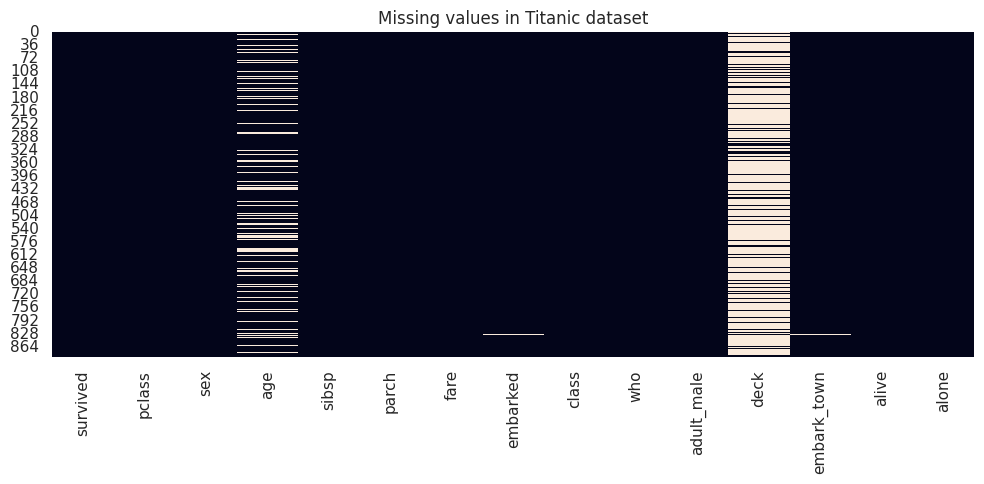

In [5]:
print(titanic.isnull().sum()); print('Missing %:\n', (100*titanic.isnull().mean()).round(2))
plt.figure(figsize=(10,5)); sns.heatmap(titanic.isnull(),cbar=False); plt.title('Missing values in Titanic dataset'); plt.tight_layout(); plt.show()


**1.4 Target Variable Distribution**

Is `survived` balanced or imbalanced? This matters for how we should judge "accuracy" later in Part 3.

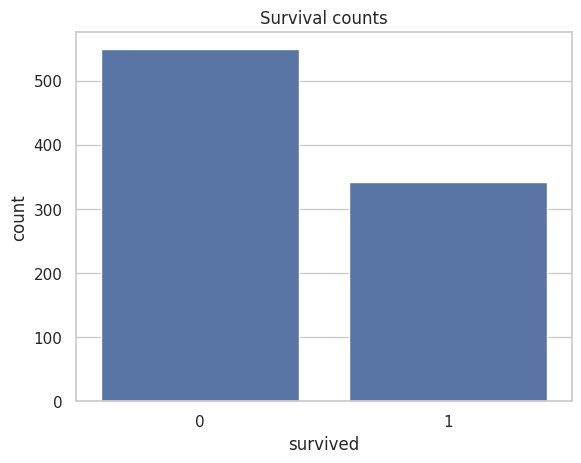

survived
0    61.62
1    38.38
Name: proportion, dtype: float64


In [6]:
sns.countplot(data=titanic,x='survived'); plt.title('Survival counts'); plt.show(); print((titanic['survived'].value_counts(normalize=True)*100).round(2))


**1.5 Univariate Analysis**

Look at `age` and `fare` individually — shape of distribution, and whether they look skewed (relevant for Member B's transformation step later).

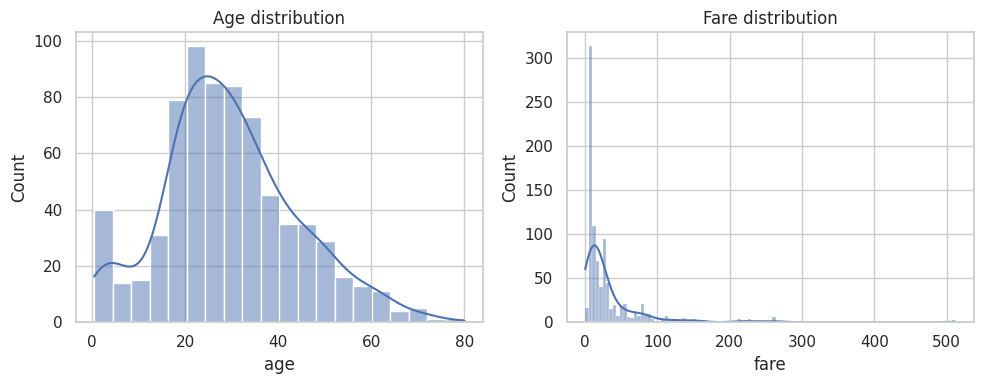

Age skew: 0.38910778230082704
Fare skew: 4.787316519674893


In [7]:
fig,axes=plt.subplots(1,2,figsize=(10,4)); sns.histplot(data=titanic,x='age',kde=True,ax=axes[0]); sns.histplot(data=titanic,x='fare',kde=True,ax=axes[1]); axes[0].set_title('Age distribution'); axes[1].set_title('Fare distribution'); plt.tight_layout(); plt.show(); print('Age skew:',titanic['age'].skew()); print('Fare skew:',titanic['fare'].skew())


**1.6 Bivariate Analysis — Does Survival Depend on Sex and Class?**

Compute and visualize survival rate broken down by `sex`, and separately by `pclass`.

sex
female    0.742038
male      0.188908
Name: survived, dtype: float64
pclass
1    0.629630
2    0.472826
3    0.242363
Name: survived, dtype: float64


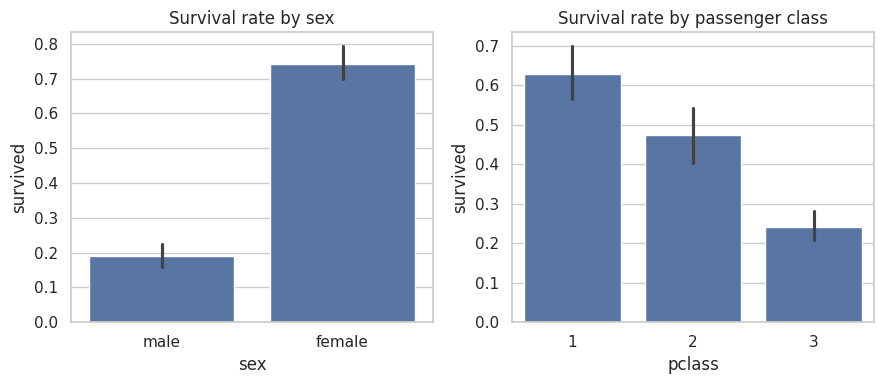

In [8]:
sex_survival=titanic.groupby('sex',observed=False)['survived'].mean(); class_survival=titanic.groupby('pclass',observed=False)['survived'].mean(); print(sex_survival); print(class_survival)
fig,axes=plt.subplots(1,2,figsize=(9,4)); sns.barplot(data=titanic,x='sex',y='survived',ax=axes[0]); sns.barplot(data=titanic,x='pclass',y='survived',ax=axes[1]); axes[0].set_title('Survival rate by sex'); axes[1].set_title('Survival rate by passenger class'); plt.tight_layout(); plt.show()


**1.7 Connecting to Bayes' Theorem**

Recall **Bayes' Theorem**:

$$P(A \mid B) = \frac{P(B \mid A)\, P(A)}{P(B)}$$

Let's estimate, **by hand**, the probability a passenger survived *given* they were female — i.e. $P(\text{Survived}=1 \mid \text{Sex}=\text{female})$ — using only priors and likelihoods computed from the data (not `groupby` directly), and then check it against the true empirical value from Section 1.6.

- $P(A) = P(\text{Survived}=1)$ → the overall survival rate
- $P(B) = P(\text{Sex}=\text{female})$ → the overall proportion of female passengers
- $P(B \mid A) = P(\text{Sex}=\text{female} \mid \text{Survived}=1)$ → among survivors, what fraction were female?

In [9]:
P_A=titanic['survived'].mean(); P_B=(titanic['sex']=='female').mean(); survivors=titanic[titanic['survived']==1]; P_B_given_A=(survivors['sex']=='female').mean(); P_A_given_B=(P_B_given_A*P_A)/P_B
print('P(Survived):',P_A); print('P(Female):',P_B); print('P(Female | Survived):',P_B_given_A); print('P(Survived | Female) by Bayes:',P_A_given_B); print('Direct P(Survived | Female):',titanic.groupby('sex')['survived'].mean()['female'])


P(Survived): 0.3838383838383838
P(Female): 0.35241301907968575
P(Female | Survived): 0.6812865497076024
P(Survived | Female) by Bayes: 0.7420382165605095
Direct P(Survived | Female): 0.7420382165605095


**💡 Why this matters:** Naive Bayes classifiers work by applying exactly this formula to **every feature**, multiplying the likelihoods together under the "naive" independence assumption — Member C will build on this in Part 3.

**Hand off to Member B:** the raw `titanic` DataFrame, plus your findings on which columns are missing and which numeric columns are skewed.

#### **Part 2 (Member B): Data Cleaning, Transformation & Encoding**

**Your job:** take the raw `titanic` DataFrame and Member A's findings, and produce a fully cleaned, encoded, scaled, model-ready `X_train_final` / `X_test_final`.

**2.1 Selecting Columns and Splitting Train/Test First**

We split **before** cleaning so every fitted step (imputer, encoder, scaler) is learned only from `X_train` — this avoids **data leakage** into the test set.

In [10]:
from sklearn.model_selection import train_test_split
cols=['pclass','sex','age','sibsp','parch','fare','embarked','survived']; df=titanic[cols].copy()
X=df.drop(columns=['survived']); y=df['survived']
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)


**2.2 Handling Missing Values**

From Part 1.3, `age` and `embarked` have missing values. Impute `age` with the **median** (robust to skew) and `embarked` with the **mode** (most frequent category) — fit on train, apply to both.

In [11]:
from sklearn.impute import SimpleImputer
num_imputer=SimpleImputer(strategy='median'); X_train['age']=num_imputer.fit_transform(X_train[['age']]).ravel(); X_test['age']=num_imputer.transform(X_test[['age']]).ravel()
cat_imputer=SimpleImputer(strategy='most_frequent'); X_train['embarked']=cat_imputer.fit_transform(X_train[['embarked']]).ravel(); X_test['embarked']=cat_imputer.transform(X_test[['embarked']]).ravel()
print('Train missing:\n',X_train.isnull().sum()); print('Test missing:\n',X_test.isnull().sum())


Train missing:
 pclass      0
sex         0
age         0
sibsp       0
parch       0
fare        0
embarked    0
dtype: int64
Test missing:
 pclass      0
sex         0
age         0
sibsp       0
parch       0
fare        0
embarked    0
dtype: int64


**2.3 Binning — Creating an `age_group` Feature (Custom Binning)**

Convert continuous `age` into meaningful, ordered groups using domain knowledge — a **custom binning** approach, with edges we choose ourselves:

`Child (0–12)` < `Teen (13–19)` < `Adult (20–59)` < `Senior (60+)`

In [12]:
age_bins=[0,12,19,59,100]; age_labels=['Child','Teen','Adult','Senior']
X_train['age_group']=pd.cut(X_train['age'],bins=age_bins,labels=age_labels,include_lowest=True); X_test['age_group']=pd.cut(X_test['age'],bins=age_bins,labels=age_labels,include_lowest=True)
print(X_train['age_group'].value_counts()); print(X_test['age_group'].value_counts())


age_group
Adult     565
Teen       74
Child      55
Senior     18
Name: count, dtype: int64
age_group
Adult     136
Teen       21
Child      14
Senior      8
Name: count, dtype: int64


**2.4 Binning — `fare_level` Feature (Unsupervised, Quantile Binning)**

Now try an **unsupervised** binning method on `fare`: split it into 4 **equal-frequency (quantile)** bins using `KBinsDiscretizer`, fit only on the training data.

In [13]:
from sklearn.preprocessing import KBinsDiscretizer
kb=KBinsDiscretizer(n_bins=4,encode='ordinal',strategy='quantile', subsample=None); X_train['fare_level']=kb.fit_transform(X_train[['fare']]).ravel(); X_test['fare_level']=kb.transform(X_test[['fare']]).ravel(); print('Fare bin edges:',kb.bin_edges_)


Fare bin edges: [array([  0.    ,   7.8958,  14.4542,  31.    , 512.3292])]


**2.5 Binarization**

Create a simple binary flag: `is_child` = 1 if `age` < 13, else 0 — using `Binarizer`.

In [14]:
from sklearn.preprocessing import Binarizer
binarizer=Binarizer(threshold=12.9); X_train['is_child']=(1-binarizer.fit_transform(X_train[['age']])).ravel(); X_test['is_child']=(1-binarizer.transform(X_test[['age']])).ravel()


**2.6 Encoding Categorical Features**

Three different encoders for three different situations:

- **Ordinal Encoding** → `age_group` has a real order (`Child < Teen < Adult < Senior`), so use `OrdinalEncoder` with that explicit order.
- **One-Hot Encoding** → `sex` and `embarked` are nominal (no order), so use `OneHotEncoder`.
- **Label Encoding** → as a quick demo only: label-encode `titanic['alive']` (the text `yes`/`no` version of the target) separately, just to see how `LabelEncoder` works on a target-like column. (We won't use this encoded column in modeling — `survived` is already numeric.)

In [15]:
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, LabelEncoder
oe=OrdinalEncoder(categories=[['Child','Teen','Adult','Senior']]); X_train['age_group_encoded']=oe.fit_transform(X_train[['age_group']]).ravel(); X_test['age_group_encoded']=oe.transform(X_test[['age_group']]).ravel()
le=LabelEncoder(); alive_encoded=le.fit_transform(titanic['alive']); print('Alive classes:',le.classes_); print('First 10 encoded:',alive_encoded[:10])


Alive classes: ['no' 'yes']
First 10 encoded: [0 1 1 1 0 0 0 0 1 1]


**2.7 Combining Everything with `ColumnTransformer`**

Instead of manually encoding and concatenating column-by-column, bundle the remaining raw categorical columns (`sex`, `embarked`) into one `ColumnTransformer`, and pass the already-processed numeric/ordinal columns straight through.

In [16]:
from sklearn.compose import ColumnTransformer
# Transform sex and embarked to indicator columns; keep all other numeric features.
ct=ColumnTransformer([('ohe',OneHotEncoder(drop='first',handle_unknown='ignore'),['sex','embarked'])],remainder='passthrough',verbose_feature_names_out=False)
feature_cols=['sex','embarked','pclass','age','sibsp','parch','fare','age_group_encoded','fare_level','is_child']
X_train_ready=X_train[feature_cols].copy(); X_test_ready=X_test[feature_cols].copy()
X_train_encoded=ct.fit_transform(X_train_ready); X_test_encoded=ct.transform(X_test_ready)
print('Encoded shapes:',X_train_encoded.shape,X_test_encoded.shape)


Encoded shapes: (712, 11) (179, 11)


**2.8 Reducing Skew — Power Transformer**

From Part 1.5, `fare` is heavily right-skewed. Apply a `PowerTransformer` (Yeo-Johnson, since `fare` can be 0) to `fare` before scaling.

In [17]:
from sklearn.preprocessing import PowerTransformer
pt=PowerTransformer(method='yeo-johnson'); fare_before=X_train['fare'].skew(); X_train['fare']=pt.fit_transform(X_train[['fare']]).ravel(); X_test['fare']=pt.transform(X_test[['fare']]).ravel(); print('Fare skew before:',fare_before); print('Fare skew after:',X_train['fare'].skew())
# Rebuild encoded arrays after transforming fare.
X_train_ready=X_train[feature_cols].copy(); X_test_ready=X_test[feature_cols].copy(); X_train_encoded=ct.fit_transform(X_train_ready); X_test_encoded=ct.transform(X_test_ready)


Fare skew before: 4.64618995113625
Fare skew after: -0.030504795464933083


**2.9 Feature Scaling — Standardization vs Normalization**

Two common scaling techniques:

- **Standardization (Z-score):** $x' = \dfrac{x - \mu}{\sigma}$ → mean 0, std 1. Use `StandardScaler`.
- **Normalization (Min-Max):** $x' = \dfrac{x - \min(x)}{\max(x) - \min(x)}$ → scales to a fixed $[0,1]$ range. Use `MinMaxScaler`.

Pick **one** to apply to the final numeric columns (e.g., `age`, `fare`) — fit on train, transform both.

In [18]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler(); X_train_final=scaler.fit_transform(X_train_encoded); X_test_final=scaler.transform(X_test_encoded)
print('Final shapes:',X_train_final.shape,X_test_final.shape)


Final shapes: (712, 11) (179, 11)


**Hand off to Member C:** `X_train_final`, `X_test_final`, `y_train`, `y_test` — the model-ready data.

#### **Part 3 (Member C): Naive Bayes Modeling, Cross-Validation & Evaluation**

**Your job:** train Naive Bayes two ways (from scratch and with `sklearn`), validate it properly, and compare results — including whether Member B's preprocessing actually helped.

**3.1 Bayes' Theorem Recap → the Naive Bayes Formula**

Member A estimated $P(\text{Survived} \mid \text{Sex})$ for **one** feature by hand in Section 1.7. Naive Bayes generalizes this to **all** features at once, assuming they're conditionally independent given the class:

$$P(y \mid x_1, ..., x_n) \propto P(y) \prod_{i=1}^{n} P(x_i \mid y)$$

- $P(y)$ → the **prior** (class probability, e.g. overall survival rate)
- $P(x_i \mid y)$ → the **likelihood** of feature $i$ given the class (for continuous features, modeled with a Gaussian):

$$P(x_i \mid y) = \frac{1}{\sqrt{2\pi\sigma_y^2}} \exp\left(-\frac{(x_i - \mu_y)^2}{2\sigma_y^2}\right)$$

- The predicted class is whichever $y$ **maximizes** this product (in practice, the **sum of log-probabilities**, to avoid numerical underflow).

**3.2 Implementing Gaussian Naive Bayes From Scratch**

Follow the 3-step process below.

In [19]:
class GaussianNaiveBayesScratch:
    def fit(self,X,y):
        X=np.asarray(X,dtype=float); y=np.asarray(y); self.classes=np.unique(y); self.priors={}; self.mean={}; self.var={}
        for c in self.classes:
            X_c=X[y==c]; self.priors[c]=len(X_c)/len(y); self.mean[c]=X_c.mean(axis=0); self.var[c]=np.maximum(X_c.var(axis=0),1e-9)
        return self
    def _joint_log_likelihood(self,X,c):
        X=np.asarray(X,dtype=float); var=self.var[c]; mean=self.mean[c]
        return np.log(self.priors[c]) - 0.5*np.sum(np.log(2*np.pi*var)+(X-mean)**2/var,axis=1)
    def predict(self,X):
        scores=np.column_stack([self._joint_log_likelihood(X,c) for c in self.classes]); return self.classes[np.argmax(scores,axis=1)]


**3.3 Naive Bayes Using `scikit-learn` (`GaussianNB`)**

`sklearn` provides several Naive Bayes variants depending on feature type — we use `GaussianNB` since our features are continuous after Part 2's scaling:
- `GaussianNB` → continuous features (our case)
- `MultinomialNB` → discrete counts (e.g., word frequencies in text)
- `BernoulliNB` → binary/boolean features
- `CategoricalNB` → raw categorical features (discrete, unencoded)

In [20]:
from sklearn.naive_bayes import GaussianNB
model=GaussianNB(); model.fit(X_train_final,y_train); y_pred_sklearn=model.predict(X_test_final)
scratch=GaussianNaiveBayesScratch().fit(X_train_final,y_train); y_pred_scratch=scratch.predict(X_test_final)


**3.4 Cross-Validation for a More Reliable Estimate**

A single train/test split can be lucky or unlucky. `cross_val_score` repeats training/evaluation across multiple folds and averages the results:

$$\text{CV Score} = \frac{1}{k}\sum_{i=1}^{k} \text{Accuracy}_i$$

In [21]:
from sklearn.model_selection import cross_val_score
cv_scores=cross_val_score(GaussianNB(),X_train_final,y_train,cv=5); print('Fold scores:',cv_scores); print('Mean:',cv_scores.mean()); print('Std:',cv_scores.std())


Fold scores: [0.72727273 0.76923077 0.78169014 0.8028169  0.75352113]
Mean: 0.7669063331035162
Std: 0.02554806979255402


**3.5 Model Evaluation — Accuracy & Confusion Matrix**

- **Accuracy:** $\dfrac{TP + TN}{TP + TN + FP + FN}$ — overall correctness (less informative if classes are imbalanced, per Part 1.4).
- **Confusion Matrix:** shows exactly which classes get confused with which.

Scratch accuracy: 0.7597765363128491
sklearn accuracy: 0.7597765363128491


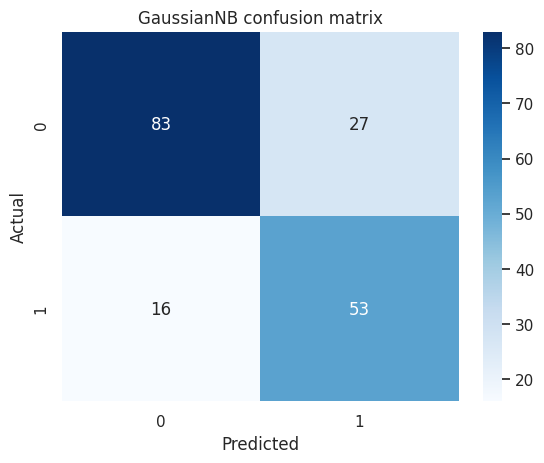

              precision    recall  f1-score   support

           0       0.84      0.75      0.79       110
           1       0.66      0.77      0.71        69

    accuracy                           0.76       179
   macro avg       0.75      0.76      0.75       179
weighted avg       0.77      0.76      0.76       179



In [22]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
print('Scratch accuracy:',accuracy_score(y_test,y_pred_scratch)); print('sklearn accuracy:',accuracy_score(y_test,y_pred_sklearn))
cm=confusion_matrix(y_test,y_pred_sklearn); sns.heatmap(cm,annot=True,fmt='d',cmap='Blues'); plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title('GaussianNB confusion matrix'); plt.show(); print(classification_report(y_test,y_pred_sklearn))


**3.6 Final Comparison: Does All That Preprocessing Actually Help?**

Train one more `GaussianNB` on a **minimally processed** baseline (just impute missing `age`, drop other categorical columns) and compare its cross-validated accuracy to Member B's fully processed pipeline from Section 3.4.

In [23]:
from sklearn.model_selection import cross_val_score
X_baseline=titanic[['pclass','age','sibsp','parch','fare']].copy(); X_baseline['age']=SimpleImputer(strategy='median').fit_transform(X_baseline[['age']]).ravel(); y=titanic['survived']
baseline_scores=cross_val_score(GaussianNB(),X_baseline,y,cv=5); processed_scores=cross_val_score(GaussianNB(),X_train_final,y_train,cv=5)
print('Baseline mean CV accuracy:',baseline_scores.mean()); print('Processed mean CV accuracy:',processed_scores.mean())
# Compare the means; preprocessing is useful if it improves average cross-validation accuracy.


Baseline mean CV accuracy: 0.6768438892724876
Processed mean CV accuracy: 0.7669063331035162


**Compare your 3 results:** from-scratch NB, `sklearn` NB on the full pipeline, and `sklearn` NB on the raw baseline. They should mostly agree in *direction* even if the exact numbers differ slightly.

#### **Wrap-Up: Group Reflection (Answer Together)**

As a group, discuss and write your answers in the cell below:

1. Which single preprocessing step from Part 2 do you think improved accuracy the most, and why?
2. How closely did your hand-computed Bayes' Theorem probability (Section 1.7) match the true empirical survival rate for women? If they didn't match exactly, why not?
3. Which Naive Bayes variant (`Gaussian`/`Multinomial`/`Bernoulli`/`Categorical`) would you choose for a spam-detection problem based on word counts, and why?
4. Why did we split the data into train/test **before** imputing, encoding, and scaling in Part 2, instead of doing it on the whole dataset first?

*Group answers here:*

1.
2.
3.
4.